In [32]:
import sys
from pathlib import Path
import pandas as pd 
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
from src.models.waterfall_engine import WaterfallEngine
DATA_DIR = ROOT / "data" / "processed"
csv_path = DATA_DIR / "default_multiplier_summary.csv"
# Optional: Apply the default clean seaborn theme
sns.set_theme()



In [39]:
mult_df = pd.read_csv(csv_path)
mult_df["date"] = pd.to_datetime(df["date"])

mult_df = mult_df.sort_values(by='date')

calibrated_mult = float(mult_df.iloc[-1]["predicted_m"])
max_mult = mult_df["empirical_m"].max()

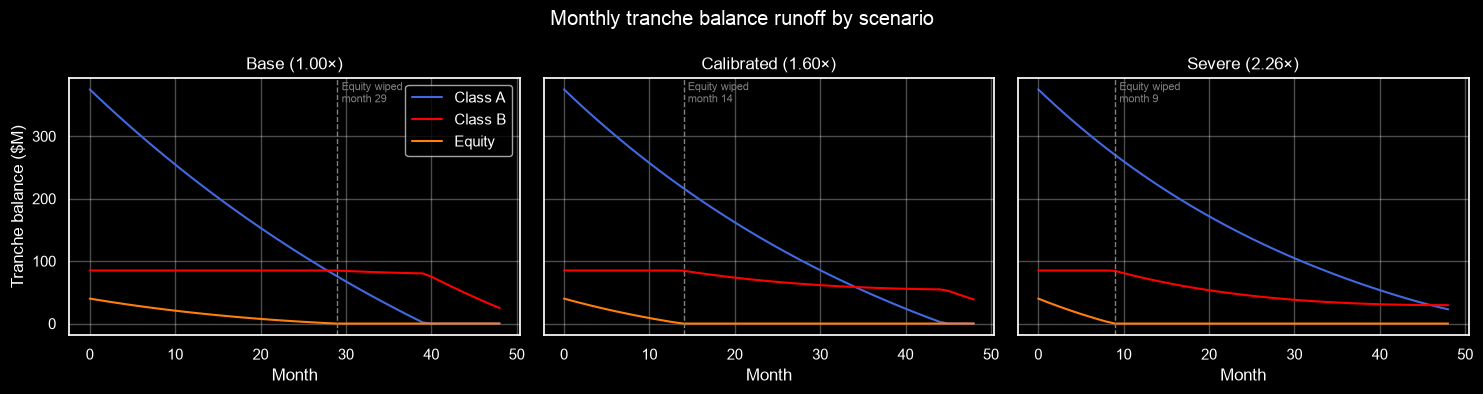

In [47]:
scenarios = {
    "Base": 1.0,
    "Calibrated": calibrated_mult,
    "Severe": max_mult,
}

scenario = []

plt.style.use("dark_background")

for key, multiplier in scenarios.items():
    engine = WaterfallEngine(default_mult=multiplier)
    outputs = engine.key_outputs()
    outputs["scenario"] = key
    scenario.append(outputs)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, (name, mult) in zip(axes, scenarios.items()):
    engine = WaterfallEngine(default_mult=mult)
    wf = engine.run_waterfall()
    outputs = engine.key_outputs()

    ax.plot(wf["period"], wf["a_end"] / 1e6, label="Class A", color="royalblue")
    ax.plot(wf["period"], wf["b_end"] / 1e6, label="Class B", color="red")
    ax.plot(wf["period"], wf["eq_end"] / 1e6, label="Equity", color='#ff7f0e')

    # Mark the month Equity is fully wiped out (if it happens)
    wipeout = outputs["equity_wipeout_period"]
    if wipeout is not None:
        ax.axvline(wipeout, color="grey", linestyle="--", linewidth=1)
        ax.text(wipeout + 0.5, ax.get_ylim()[1] * 0.9, f"Equity wiped\nmonth {wipeout}",
                fontsize=8, color="grey")

    ax.set_title(f"{name} ({mult:.2f}×)")
    ax.set_xlabel("Month")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Tranche balance ($M)")
axes[0].legend()
fig.suptitle("Monthly tranche balance runoff by scenario")
plt.tight_layout()
plt.show()

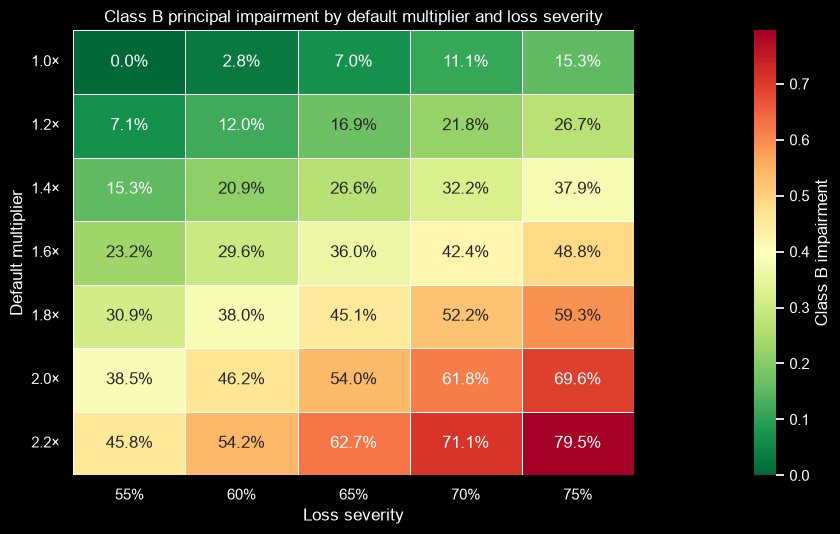

In [41]:
grid = WaterfallEngine().sensitivity()
mults = list(grid.index)
sevs = list(grid.columns)

grid_plot = grid.copy()
grid_plot.index = [f"{m:.1f}×" for m in mults]
grid_plot.columns = [f"{s:.0%}" for s in sevs]


fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(
    grid_plot, ax=ax,
    annot=True, fmt=".1%", cmap="RdYlGn_r",
    linewidths=0.5, linecolor="white", vmin=0,
    cbar_kws={"label": "Class B impairment", "pad": 0.15},
)

ax.set_title("Class B principal impairment by default multiplier and loss severity")
ax.set_xlabel("Loss severity")
ax.set_ylabel("Default multiplier")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

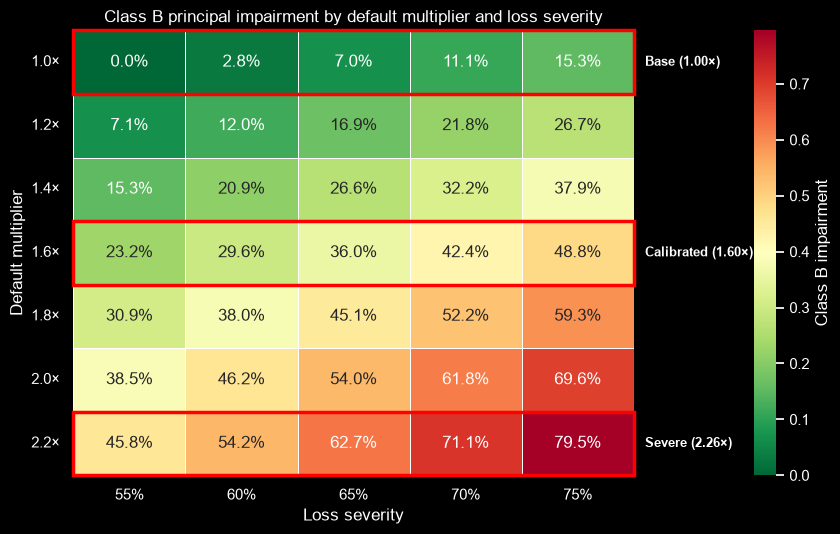

In [44]:
grid = WaterfallEngine().sensitivity()
mults = list(grid.index)
sevs = list(grid.columns)

grid_plot = grid.copy()
grid_plot.index = [f"{m:.1f}×" for m in mults]
grid_plot.columns = [f"{s:.0%}" for s in sevs]


fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(
    grid_plot, ax=ax,
    annot=True, fmt=".1%", cmap="RdYlGn_r",
    linewidths=0.5, linecolor="white", vmin=0,
    cbar_kws={"label": "Class B impairment", "pad": 0.15},
)

n_cols = grid.shape[1]
for name, m in scenarios.items():
    i = int(np.argmin([abs(row_m - m) for row_m in mults]))
    ax.add_patch(Rectangle((0, i), n_cols, 1, fill=False,
                           edgecolor="red", linewidth=2.5, clip_on=False))
    ax.text(n_cols + 0.1, i + 0.5, f"{name} ({m:.2f}×)",
            va="center", fontsize=9, fontweight="bold")

ax.set_title("Class B principal impairment by default multiplier and loss severity")
ax.set_xlabel("Loss severity")
ax.set_ylabel("Default multiplier")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()